# 01 - Data Acquisition and Exploratory Data Analysis

Dataset: UCI Heart Disease (Cleveland).

The data is first examined in its raw form, to understand its contents,
identify quality problems and decide what has to be corrected. The cleaning
and preprocessing decisions are then applied, and the features and their
relationship with heart disease are studied.

1. Data acquisition
2. Data source and scope
3. Data dictionary
4. Dataset overview
5. Data quality checks
6. Missing values
7. Target variable
8. Data cleaning and preprocessing
9. Feature distributions

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# The notebook sits in notebooks/, so the project root is one level up.
ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"

# Lets the notebook import the project code in src/ and scripts/.
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

# All figures are also saved as PNG files, so they can be used in the report.
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Data acquisition

**Objective:** The raw files are made available for the analysis. The download
is carried out by `scripts/download_data.py`, which reads one file per
hospital from the UCI repository and saves it as a CSV file.

The original hospital records have 76 columns. A 14-column version of each
hospital's data is provided by UCI in files named `processed.*.data`. The word
"processed" in these names refers to this reduction from 76 to 14 columns,
which was done by the data donors. No processing has been done in this project
at this stage, and these four files are treated as the raw data.

Files already present in `data/raw/` are reused. In this way the notebook does
not depend on the UCI website every time it is run, and the analysis is always
done on the same copy of the data.

In [2]:
from download_data import HOSPITALS, download, raw_path

for hospital in HOSPITALS:
    path = raw_path(hospital, RAW_DIR)
    if path.exists():
        status = "already present"
    else:
        download(hospital, RAW_DIR)
        status = "downloaded"
    print(f"{hospital:12s} {status:16s} {path.name}")

cleveland    already present  heart_cleveland_raw.csv
hungarian    already present  heart_hungarian_raw.csv
switzerland  already present  heart_switzerland_raw.csv
va           already present  heart_va_raw.csv


## 2. Data source and scope

**Objective:** The dataset contains records from four hospitals. The four
14-column hospital files are compared to identify which of them is suitable
for modelling.

The following is stated on the UCI dataset page:

> This database contains 76 attributes, but all published experiments refer to
> using a subset of 14 of them. In particular, the Cleveland database is the
> only one that has been used by ML researchers to date.

This statement is verified below using the data itself.

In [3]:
# Each hospital file is read into its own table.
# "?" was already read as missing by the download script.
raw = {}
for hospital in HOSPITALS:
    raw[hospital] = pd.read_csv(raw_path(hospital, RAW_DIR))

# One summary row is built for each hospital.
rows = []
for hospital, data in raw.items():
    rows.append({
        "hospital": hospital,
        "patients": len(data),
        # A complete row has no missing value in any of the 14 columns.
        "complete rows": len(data.dropna()),
        # Cholesterol can never be 0 in a living person, so 0 means "not measured".
        "chol recorded as 0": int((data["chol"] == 0).sum()),
        # "num" above 0 means disease. The mean of True/False values is the share of True.
        "patients with disease (%)": round((data["num"] > 0).mean() * 100),
    })

summary = pd.DataFrame(rows).set_index("hospital")
summary

,patients,complete rows,chol recorded as 0,patients with disease (%)
hospital,,,,
cleveland,303,297,0,46
hungarian,294,1,0,36
switzerland,123,0,123,93
va,200,1,49,74


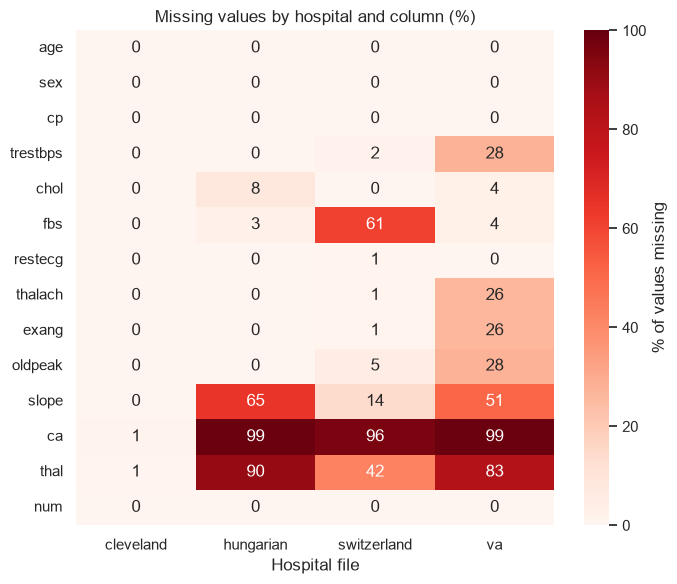

In [4]:
# Share of missing values in every column, for every hospital.
# isna() marks each empty cell as True, so the mean of a column is the share
# of empty cells in it.
missing_pct = pd.DataFrame()
for hospital, data in raw.items():
    missing_pct[hospital] = data.isna().mean() * 100

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(missing_pct, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% of values missing"}, ax=ax)
ax.set_title("Missing values by hospital and column (%)")
ax.set_xlabel("Hospital file")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_missing_by_hospital.png", dpi=150)
plt.show()

**Observations**

- The Cleveland file has 297 complete rows out of 303. Only 2 complete rows
  out of 617 are found in the other three files taken together.
- `ca` is missing for 99% of the Hungarian, 96% of the Switzerland and 99% of
  the VA patients. `thal` is missing for 90%, 42% and 83%, and `slope` for
  65%, 14% and 51%.
- In the Switzerland file, cholesterol is recorded as 0 for all 123 patients,
  and in the VA file for 49 patients. A cholesterol of 0 is not possible, so
  these are missing values stored as a number.
- The share of patients with disease differs widely: 46% in Cleveland, 36% in
  Hungarian, 93% in Switzerland and 74% in VA.

**Inference**

- The UCI statement is supported by the data. Only the Cleveland file is
  complete enough for training a model.
- If the other files were included, `ca`, `thal` and `slope` would have to be
  filled for more than half of the patients. This would amount to creating
  data that was never recorded.
- Since the disease share differs so much between hospitals, a model trained
  on the combined data could learn the hospital in place of the patient's risk.

**Decision**

- Only the Cleveland file (303 patients, 14 columns) is used for modelling.
- The other three files are retained in `data/raw/` only for this comparison.

## 3. Data dictionary

**Objective:** The meaning and the type of each column are recorded, as given
in the UCI documentation (`heart-disease.names`).

The types used are the standard ones:

- **Numerical** - a quantity. It is *continuous* when it is a measurement and
  *discrete* when it is a count.
- **Categorical** - a group label. It is *binary* when there are two groups,
  *nominal* when the groups have no order, and *ordinal* when they have a
  natural order.

The categorical features are stored as number codes in the file. A code such
as `cp = 4` is only a label for a category and has no numeric meaning.

| Column | Meaning | Type | Values |
|---|---|---|---|
| `age` | Age of the patient | Numerical (continuous) | years, recorded as whole numbers |
| `sex` | Sex | Categorical (binary) | 1 = male, 0 = female |
| `cp` | Chest pain type | Categorical (nominal) | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = no symptoms |
| `trestbps` | Resting blood pressure at admission | Numerical (continuous) | mm Hg |
| `chol` | Serum cholesterol | Numerical (continuous) | mg/dl |
| `fbs` | Fasting blood sugar above 120 mg/dl | Categorical (binary) | 1 = yes, 0 = no |
| `restecg` | Resting ECG result | Categorical (nominal) | 0 = normal, 1 = ST-T wave abnormality, 2 = left ventricular hypertrophy |
| `thalach` | Maximum heart rate reached in the exercise test | Numerical (continuous) | beats per minute |
| `exang` | Chest pain brought on by exercise | Categorical (binary) | 1 = yes, 0 = no |
| `oldpeak` | ST depression caused by exercise, compared to rest | Numerical (continuous) | a number, 0 and above (unit not given in the documentation) |
| `slope` | Slope of the ST segment at peak exercise | Categorical (ordinal) | 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | Number of major vessels seen in fluoroscopy | Numerical (discrete) | 0 to 3 |
| `thal` | Thallium heart scan result | Categorical (nominal) | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` | Diagnosis of heart disease | Target (ordinal) | 0 = no disease, 1 to 4 = disease |

In total there are 6 numerical features (5 continuous and 1 discrete) and
7 categorical features (3 binary, 3 nominal and 1 ordinal), along with the
target.

`ca` is a count, so its type is numerical. As it takes only four values, it
can be handled by a model either as a number or as categories. This choice is
made later in this notebook, after its relationship with the target is seen.

## 4. Dataset overview

**Objective:** The size of the data, its appearance and the storage type of
each column are examined.

In [5]:
df = raw["cleveland"]
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
# One line per column: how it is stored, how many different values, how many missing.
overview = pd.DataFrame({
    "stored as": df.dtypes.astype(str),
    "different values": df.nunique(),
    "missing": df.isna().sum(),
})
overview

,stored as,different values,missing
age,float64,41,0
sex,float64,2,0
cp,float64,4,0
trestbps,float64,50,0
chol,float64,152,0
fbs,float64,2,0
restecg,float64,3,0
thalach,float64,91,0
exang,float64,2,0
oldpeak,float64,40,0


**Observations**

- The file has 303 rows and 14 columns, as stated in the UCI documentation.
- All 13 feature columns are stored as decimal numbers (`float64`), including
  the categorical ones. For example, `sex` appears as 1.0 and 0.0.
- The categorical features and `ca` have only 2 to 4 different values each.
  The continuous features have many different values.

**Inference**

- The decimal type is a result of the way the source file is written (`63.0`,
  `1.0`). It is not an error, but it hides which features are categorical.

**Decision**

- During cleaning, the categorical features are stored as whole numbers
  wherever the feature has no missing value, so that a code is read as a
  label (1, 0) and not as a quantity (1.0, 0.0). A feature with a missing
  value has to remain a decimal, because a whole-number column cannot hold an
  empty cell.
- During modelling, numerical and categorical features are treated
  differently. Numerical features are scaled, and categorical features are
  encoded, since a model would otherwise read the codes as quantities.

## 5. Data quality checks

**Objective:** The data is checked for three problems that can silently affect
a model.

1. Duplicate rows - the same patient entered twice.
2. Invalid category codes - a value that is not listed in the data dictionary.
3. Impossible values in numerical features - for example, a blood pressure of 0.

In [7]:
# 5.1 Duplicate rows
print("Duplicate rows:", int(df.duplicated().sum()))

Duplicate rows: 0


In [8]:
# 5.2 Invalid codes: the values found are compared with the values allowed
#     in the data dictionary (section 3).
VALID_CODES = {
    "sex": [0, 1],
    "cp": [1, 2, 3, 4],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [1, 2, 3],
    "ca": [0, 1, 2, 3],
    "thal": [3, 6, 7],
    "num": [0, 1, 2, 3, 4],
}

rows = []
for col, allowed in VALID_CODES.items():
    # The different values present in the column, as whole numbers.
    # Missing values are left out here. They are covered in section 6.
    found = sorted(df[col].dropna().astype(int).unique().tolist())

    # Rows whose value is not in the allowed list.
    invalid_rows = int((~df[col].dropna().isin(allowed)).sum())

    rows.append({
        "column": col,
        "values allowed": allowed,
        "values found": found,
        "rows with invalid value": invalid_rows,
    })
pd.DataFrame(rows).set_index("column")

,values allowed,values found,rows with invalid value
column,,,
sex,"[0, 1]","[0, 1]",0
cp,"[1, 2, 3, 4]","[1, 2, 3, 4]",0
fbs,"[0, 1]","[0, 1]",0
restecg,"[0, 1, 2]","[0, 1, 2]",0
exang,"[0, 1]","[0, 1]",0
slope,"[1, 2, 3]","[1, 2, 3]",0
ca,"[0, 1, 2, 3]","[0, 1, 2, 3]",0
thal,"[3, 6, 7]","[3, 6, 7]",0
num,"[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]",0


In [9]:
# 5.3 Impossible values in the continuous features.
# The limits below are wide sanity limits for a living adult. They are chosen
# only to catch entry errors (like 0 or 9999), not to judge what is healthy.
LIMITS = {
    "age": (18, 100),        # years
    "trestbps": (80, 220),   # mm Hg
    "chol": (100, 600),      # mg/dl
    "thalach": (60, 220),    # beats per minute
    "oldpeak": (0, 7),       # ST depression
}

rows = []
for col, limits in LIMITS.items():
    low = limits[0]
    high = limits[1]

    # True for each value that is below the lower limit or above the upper limit.
    too_low = df[col] < low
    too_high = df[col] > high

    rows.append({
        "column": col,
        "lowest value": df[col].min(),
        "highest value": df[col].max(),
        "allowed range": f"{low} to {high}",
        "values outside range": int(too_low.sum() + too_high.sum()),
    })
pd.DataFrame(rows).set_index("column")

,lowest value,highest value,allowed range,values outside range
column,,,,
age,29.0,77.0,18 to 100,0
trestbps,94.0,200.0,80 to 220,0
chol,126.0,564.0,100 to 600,0
thalach,71.0,202.0,60 to 220,0
oldpeak,0.0,6.2,0 to 7,0


**Observations**

- No duplicate rows are found.
- Every categorical feature, as well as `ca` and `num`, contains only the
  values listed in the data dictionary.
- All values of the continuous features lie within the sanity limits. Age
  ranges from 29 to 77
  years, resting blood pressure from 94 to 200, cholesterol from 126 to
  564, maximum heart rate from 71 to 202 and `oldpeak` from 0 to 6.2.
- Unlike the Switzerland and VA files, the Cleveland file has no cholesterol
  value of 0.

**Inference**

- No entry errors of the kinds checked here are present in the Cleveland file.
  The only remaining quality problem is the missing values, which are examined
  in the next section.
- Some values are high but possible, such as a cholesterol of 564. Outliers
  are studied later in this notebook.

**Decision**

- No rows are removed and no values are corrected at this stage, since no
  duplicate, invalid code or impossible value was found.
- The same checks are to be written as unit tests, so that the pipeline fails
  if invalid data is received later.

## 6. Missing values

**Objective:** The number of missing values, and the columns and patients
affected, are examined so that a suitable method of handling them can be
chosen.

In [10]:
missing = df.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string())
print()
print("Total missing values:", int(missing.sum()), "out of", df.size, "cells")
print("Rows with a missing value:", int(df.isna().any(axis=1).sum()), "out of", len(df))

Columns with missing values:
ca      4
thal    2

Total missing values: 6 out of 4242 cells
Rows with a missing value: 6 out of 303


In [11]:
# The affected rows are listed to see which patients they belong to.
missing_rows = df[df.isna().any(axis=1)]
missing_rows

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [12]:
# Rows with a missing value are compared with the complete rows.
# has_missing is True for a row that has at least one empty cell.
has_missing = df.isna().any(axis=1)

groups = {
    "complete": df[~has_missing],       # ~ means "not"
    "with missing": df[has_missing],
}

rows = []
for name, group in groups.items():
    rows.append({
        "group": name,
        "rows": len(group),
        "disease share (%)": round((group["num"] > 0).mean() * 100),
        "average age": round(group["age"].mean(), 1),
    })

compare = pd.DataFrame(rows).set_index("group")
compare

,rows,disease share (%),average age
group,,,
complete,297,46,54.5
with missing,6,33,49.3


**Observations**

- Only 6 values are missing out of 4,242 cells (about 0.14%). They occur in
  two columns: 4 in `ca` and 2 in `thal`.
- The 6 values belong to 6 different patients. No patient has both values
  missing.
- Of these 6 patients, 4 have no disease and 2 have disease, so both classes
  are represented.
- `thal` is a categorical feature and `ca` is a count with only four values.
  A missing value in them cannot be replaced by an average. A value such as
  `thal = 4.7` has no meaning.

**Inference**

- The amount of missing data is very small, so any reasonable method is
  expected to give almost the same model. The choice is therefore made on the
  correctness of the method.
- Three options are considered:

| Option | Method | Advantage | Limitation |
|---|---|---|---|
| A. Fill in the cleaning step | Each gap is replaced by the most common value of the column | Simple. The cleaned file has no gaps | The fill value is computed from all rows, including rows that later become test data (data leakage) |
| B. Drop the 6 rows | 297 complete rows are kept | No value is made up | 2% of a small dataset is lost. A rule is still needed in the API when a request has a missing value |
| C. Fill inside the model pipeline | The gaps are kept in the cleaned file. The most common value is learnt by the pipeline from the training data only | No leakage. The same rule is applied in the API | 6 empty cells remain in the cleaned file |

**Decision**

Option C is selected. The missing values are kept in the cleaned file and are
filled inside the model pipeline, for the following reasons.

- **Fair evaluation.** The fill value is calculated from the data. If it is
  calculated before the data is split into training and test rows, the test
  rows take part in the calculation, and the test score no longer represents
  unseen patients. Inside the pipeline, the fill value is calculated from the
  training rows only.
- **Same handling in training and in the API.** A request to the deployed API
  can also have a missing value. The pipeline is saved together with the
  model, so the same fill rule is applied to a new patient without any
  separate code.
- **No loss of data.** All 303 patients are retained, which matters in a
  dataset of this size.

The fill value is the most common value of the column, learnt from the
training rows. An average is not suitable, because `thal` is categorical and
`ca` takes only four whole-number values. The most common value is always a
valid value of the column.

As a consequence, 6 empty cells remain in `data/processed/heart_clean.csv`.
This is intentional and is not an omission in the cleaning.

## 7. Target variable

**Objective:** The spread of the diagnosis column `num` is examined, and the
form of the target for the model is decided.

It is stated on the UCI page that the value ranges from 0 (no disease) to 4,
and that experiments have concentrated on separating presence (1, 2, 3, 4)
from absence (0). A binary target is also required by the assignment.

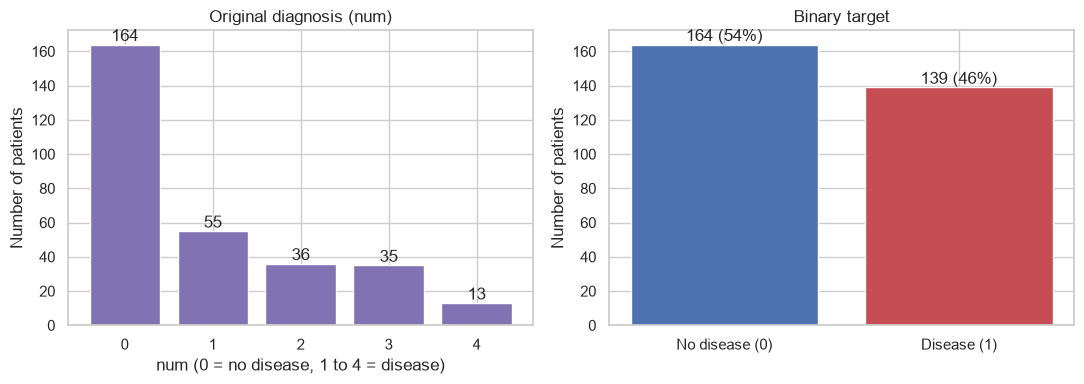

In [13]:
num_counts = df["num"].value_counts().sort_index()

# Binary version: any value above 0 means disease is present.
binary = (df["num"] > 0).astype(int)
binary_counts = binary.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(num_counts.index.astype(str), num_counts.values, color="#8172b3")
axes[0].bar_label(bars)
axes[0].set_title("Original diagnosis (num)")
axes[0].set_xlabel("num (0 = no disease, 1 to 4 = disease)")
axes[0].set_ylabel("Number of patients")

bars = axes[1].bar(["No disease (0)", "Disease (1)"], binary_counts.values,
                   color=["#4c72b0", "#c44e52"])

# Each bar is labelled with its count and its share, for example "164 (54%)".
bar_labels = []
for count in binary_counts.values:
    bar_labels.append(f"{count} ({count / len(df):.0%})")
axes[1].bar_label(bars, labels=bar_labels)
axes[1].set_title("Binary target")
axes[1].set_ylabel("Number of patients")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()

**Observations**

- In the original column, 164 patients have the value 0. The disease values
  are thinly spread: 55, 36, 35 and only 13 patients for the values 1, 2, 3
  and 4.
- After conversion to a binary target, there are 164 patients without disease
  (54%) and 139 with disease (46%).

**Inference**

- Prediction of the five original values is not practical. With only 13
  patients in the highest group, that group cannot be learnt reliably.
- The binary target is nearly balanced. Oversampling or class weights are
  therefore not required, and accuracy can be reported along with precision,
  recall and ROC-AUC.

**Decision**

- A new column `target` is created: 0 when `num` is 0, and 1 when `num` is
  1 to 4.
- The `num` column is dropped afterwards, so that it cannot leak into the
  features.

## 8. Data cleaning and preprocessing

**Objective:** The decisions taken in sections 2 to 7 are applied to the data.

Preprocessing covers every step that makes the data ready for a model.
Cleaning is the part of it that corrects problems in the data. The steps
required for this dataset, and the place where each is carried out, are listed
below.

| Step | Carried out in | Reason |
|---|---|---|
| Only the Cleveland file is used | `scripts/download_data.py` | Only this file is nearly complete (section 2) |
| Storage type of categorical features corrected | `src/data_prep.py` | A fixed correction. Nothing is learnt from the data |
| Binary `target` created and `num` dropped | `src/data_prep.py` | A fixed rule (section 7) |
| Missing values filled | Model pipeline | The fill value is learnt from the training rows only (section 6) |
| Categorical features encoded | Model pipeline | The categories are learnt from the training rows, and the same encoding is applied in the API |
| Numerical features scaled | Model pipeline | The mean and spread are learnt from the training rows only |

The rule followed is this: a step based on a fixed rule is applied in the
cleaning script, and a step that learns something from the data is placed in
the model pipeline. In this way nothing is learnt from the test rows, and the
deployed API applies exactly the same steps as the training.

No rows are removed, since no duplicate, invalid code or impossible value was
found (section 5). The same checks are repeated as unit tests in `tests/`.

The cleaning script `src/data_prep.py` is run from the cell below, and
`data/processed/heart_clean.csv` is saved.

In [14]:
from src.data_prep import CATEGORICAL, NUMERIC, TARGET, prepare

# prepare() reads the raw CSV, cleans it, saves the cleaned CSV and returns it.
clean_df = prepare(
    raw_path=raw_path("cleveland", RAW_DIR),
    clean_path=ROOT / "data" / "processed" / "heart_clean.csv",
)

print("Shape after cleaning:", clean_df.shape)
print("Missing values left for the pipeline:", int(clean_df.isna().sum().sum()))
print()
print("Target counts:")
print(clean_df[TARGET].value_counts().sort_index().to_string())

Shape after cleaning: (303, 14)
Missing values left for the pipeline: 6

Target counts:
target
0    164
1    139


In [15]:
# The cleaned data is checked to confirm that only the intended changes were made.
features = NUMERIC + CATEGORICAL

# 1. No row was added or removed.
assert len(clean_df) == len(df)

# 2. Feature values are the same as in the raw file (only the storage type changed).
assert clean_df[features].astype(float).equals(df[features].astype(float))

# 3. The target follows the rule "num above 0 means disease".
assert (clean_df[TARGET] == (df["num"] > 0).astype(int)).all()

print("All three checks passed.")

# Storage type of each column after cleaning (shown sideways to save space).
pd.DataFrame({"stored as": clean_df.dtypes.astype(str)}).T

All three checks passed.


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
stored as,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,float64,float64,int64


**Observations**

- The cleaned file has 303 rows and 14 columns: 13 features and `target`.
- 6 missing values remain, as decided in section 6.
- The target has 164 patients without disease and 139 with disease.
- The categorical features without missing values are now stored as whole
  numbers. `ca` and `thal` remain as decimals because they still contain
  empty cells.

**Inference**

- Very little cleaning is required, because the Cleveland file was already in
  good condition. Most of the effort so far went into confirming this and
  not assuming it.
- All later work (the remaining sections, training, tests and the API) starts
  from `data/processed/heart_clean.csv`.

## 9. Feature distributions

**Objective:** The distribution of each feature is examined on its own, to
understand its range and shape, and to identify categories with very few
patients. The cleaned data is used from this section onwards.

### 9.1 Continuous features

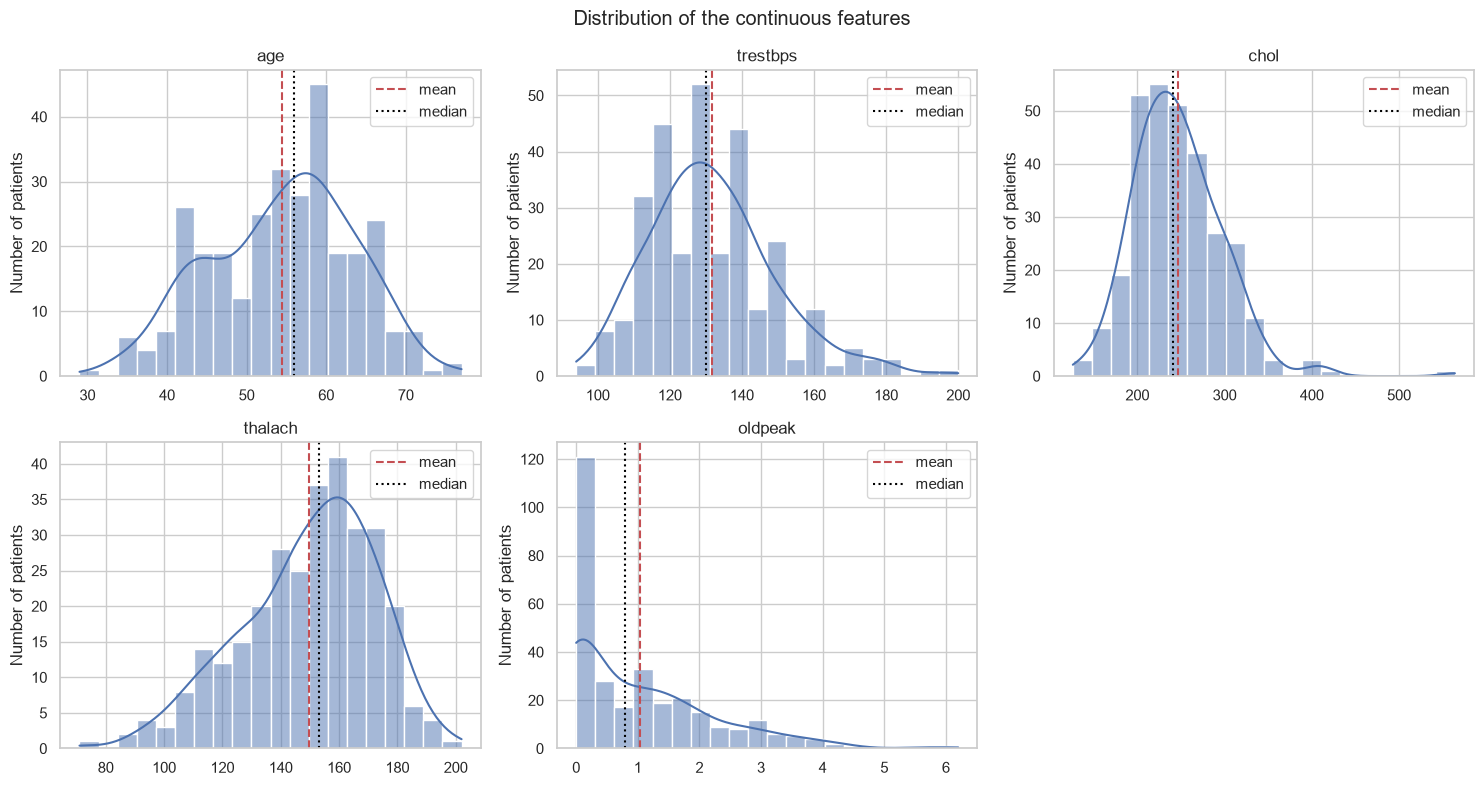

In [16]:
data = clean_df   # the cleaned data from section 8

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()   # the 2 x 3 grid of plots as a simple list

for i, col in enumerate(NUMERIC):
    ax = axes[i]
    sns.histplot(data[col], bins=20, kde=True, color="#4c72b0", ax=ax)

    # The mean and the median are marked. A gap between the two lines shows
    # that the distribution is skewed (stretched to one side).
    ax.axvline(data[col].mean(), color="#c44e52", linestyle="--", label="mean")
    ax.axvline(data[col].median(), color="black", linestyle=":", label="median")

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Number of patients")
    ax.legend()

axes[5].axis("off")   # there are five features, so the sixth plot is left empty
fig.suptitle("Distribution of the continuous features")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_numerical_histograms.png", dpi=150)
plt.show()

In [17]:
# Summary numbers for the same features.
# Skewness is 0 for a symmetric distribution. A positive value means a long
# tail towards high values, and a negative value a long tail towards low values.
stats = data[NUMERIC].agg(["mean", "median", "std", "min", "max", "skew"]).T
stats.round(2)

,mean,median,std,min,max,skew
age,54.44,56.0,9.04,29.0,77.0,-0.21
trestbps,131.69,130.0,17.60,94.0,200.0,0.71
chol,246.69,241.0,51.78,126.0,564.0,1.14
thalach,149.61,153.0,22.88,71.0,202.0,-0.54
oldpeak,1.04,0.8,1.16,0.0,6.2,1.27


**Observations**

- `age` is nearly symmetric (skewness -0.21), with a mean of 54.4 and a median
  of 56 years. 206 of the 303 patients are between 50 and 69 years, and only
  15 are below 40.
- `thalach` is slightly skewed to the left (-0.54), with a mean of 149.6 and a
  median of 153.
- `trestbps` (0.71), `chol` (1.14) and `oldpeak` (1.27) are skewed to the
  right. A small number of patients have high values.
- `oldpeak` is exactly 0 for 99 patients (33%), so its distribution is not
  bell-shaped.
- The ranges are very different. `oldpeak` lies between 0 and 6.2, while
  `chol` lies between 126 and 564.

**Inference**

- Because the ranges differ so much, a model that is sensitive to scale, such
  as Logistic Regression, would give more weight to the features with large
  numbers.
- The skew is moderate. Tree-based models are not affected by it. A log
  transformation is also not possible for `oldpeak` as it stands, because the
  logarithm of 0 is not defined.
- The patients are mostly middle-aged and older. The trained model cannot be
  relied upon for young adults, as very few of them are present in the data.

**Decision**

- The numerical features are standardised (mean 0, standard deviation 1)
  inside the model pipeline.
- No transformation is applied for the skew.
- The high values are examined as possible outliers in the next section.

### 9.2 Categorical features and `ca`

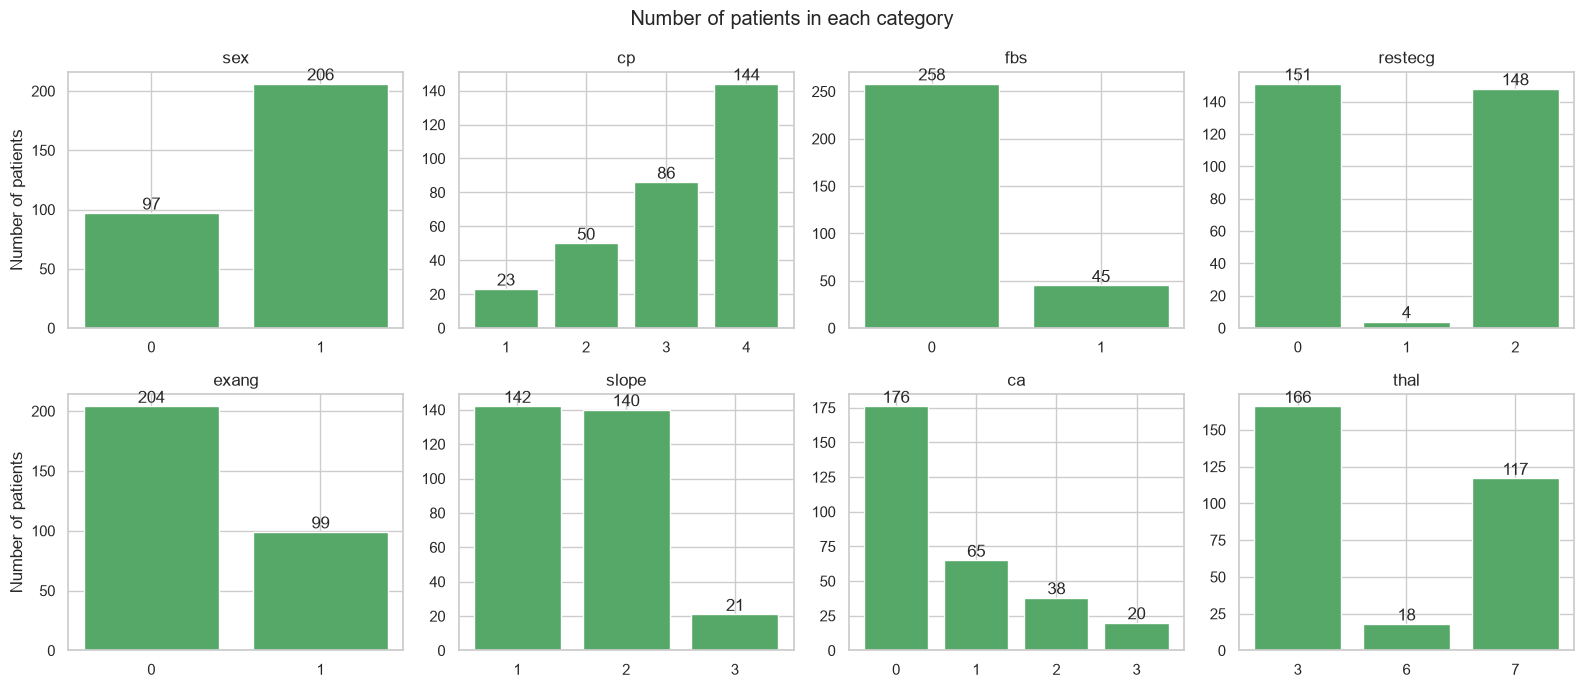

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()

for i, col in enumerate(CATEGORICAL):
    ax = axes[i]

    # Number of patients in each category. Missing values are not counted,
    # so the bars of "ca" and "thal" add up to 299 and 301.
    counts = data[col].value_counts().sort_index()

    # The codes are shown as whole numbers on the axis.
    labels = []
    for code_value in counts.index:
        labels.append(str(int(code_value)))

    bars = ax.bar(labels, counts.values, color="#55a868")
    ax.bar_label(bars)
    ax.set_title(col)

axes[0].set_ylabel("Number of patients")
axes[4].set_ylabel("Number of patients")
fig.suptitle("Number of patients in each category")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_categorical_counts.png", dpi=150)
plt.show()

In [19]:
# The smallest category of each feature, to find categories with very few patients.
rows = []
for col in CATEGORICAL:
    counts = data[col].value_counts()
    rows.append({
        "feature": col,
        "smallest category": int(counts.idxmin()),
        "patients": int(counts.min()),
        "share (%)": round(counts.min() / len(data) * 100, 1),
    })

pd.DataFrame(rows).set_index("feature").sort_values("patients")

,smallest category,patients,share (%)
feature,,,
restecg,1,4,1.3
thal,6,18,5.9
ca,3,20,6.6
slope,3,21,6.9
cp,1,23,7.6
fbs,1,45,14.9
sex,0,97,32.0
exang,1,99,32.7


**Observations**

- 206 patients (68%) are male and 97 (32%) are female.
- Nearly half of the patients (144, or 47.5%) have chest pain type 4, which
  means no chest pain symptoms.
- `restecg = 1` occurs in only 4 patients (1.3%).
- Three more categories have fewer than 25 patients each: `thal = 6` (18),
  `ca = 3` (20) and `slope = 3` (21). `cp = 1` has 23.
- Fasting blood sugar is high (`fbs = 1`) in 45 patients (15%).

**Inference**

- A category with very few patients gives little information to a model. The
  effect estimated for `restecg = 1` from 4 patients cannot be trusted.
- During cross-validation, the data is divided into parts. A part used for
  training may contain no patient with `restecg = 1`, while the part used for
  testing contains one. The encoder must not fail in this case.
- The data is dominated by male patients, so the results for women rest on
  97 patients. This is examined in the subgroup check.

**Decision**

- The rare categories are retained and not merged with others, since merging
  medical categories needs a clinical reason.
- The encoder in the pipeline is set to ignore a category that was not seen
  during training.